# The band structure of a defect: unfolding a supercell

A vacancy breaks the translation symmetry of the crystal, so to compute it we need
a supercell. The bands of the supercell are folded into its small Brillouin zone,
and they are hard to compare with the bands of the perfect crystal. Unfolding
answers a simpler question: how much of each supercell state has the character of
a Bloch state of the primitive cell at $\mathbf k$? This is the spectral function
$A(\mathbf k, E)$, and it is what ARPES measures on a crystal with defects.

Here we compute it for a silicon supercell of 8 sites with one vacancy, with no
supercell band at all, by the kernel polynomial method. For the perfect supercell
the weight falls exactly on the bands of the two-atom cell, and with the vacancy it
spreads and moves.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from defuqumat import Calculator

si = dict(pseudos={'Si': 'Si.pz-vbc.UPF'}, pseudo_dir='../tests/data/pseudo', ecut=163.3)
primitive = Calculator.from_keywords(lattice='fcc', a=5.43, atoms=[('Si', (0, 0, 0)), ('Si', (0.25, 0.25, 0.25))],
                                     kmesh=(4, 4, 4), **si)
path = primitive.kpath('L-G-X', 40)
bands = primitive.get_bands(path, nbnd=8)
kpoints, lattice = np.asarray(path.crystal(primitive.system.cell)), np.asarray(primitive.system.cell.at)

[defuqumat] a band structure: no ground state cached, running the SCF first (conv_thr = 1e-06). Call get_scf() to do this explicitly.


## What is computed

The supercell Hamiltonian is taken at the primitive $\mathbf k$ itself. Among its
plane waves $|\mathbf k + \mathbf G\rangle$, those with $\mathbf G$ a reciprocal
vector of the primitive cell carry the crystal momentum $\mathbf k$ of the primitive
cell. The spectral function is the trace of $\delta(E - H)$ over them:

$$A(\mathbf k, E) = \sum_{\mathbf G_p} \langle \mathbf k + \mathbf G_p|\,\delta(E - H)\,|\mathbf k + \mathbf G_p\rangle
= \sum_n \sum_{\mathbf G_p} |c_{n}(\mathbf k + \mathbf G_p)|^2\,\delta(E - \varepsilon_n).$$

In a perfect crystal these plane waves do not mix with the others, so $A$ is a
sum of delta functions at the primitive bands. We expand $\delta(E - H)$ in
Chebyshev polynomials of $H$, as for the density of states, and take the trace with
8 random vectors on these plane waves. So no supercell band is computed.

In [2]:
sites = [(0, 0, 0), (0, .5, .5), (.5, 0, .5), (.5, .5, 0), (.25, .25, .25), (.25, .75, .75), (.75, .25, .75), (.75, .75, .25)]
spectra, weights = {}, {}
for name, atoms in (('perfect Si8', sites), ('Si8 with a vacancy', sites[1:])):
    cell = Calculator.from_keywords(lattice='cubic', a=5.43, atoms=[('Si', p) for p in atoms], kmesh=(2, 2, 2), smearing=0.1, **si)
    level = cell.get_scf().fermi_energy
    window = dict(broadening=0.01, emin=level - 1.0, emax=level + 0.4)
    spectra[name] = cell.get_kpm_unfolded(lattice, kpoints, trace='stochastic', n_random=8, **window)
    exact = cell.get_kpm_unfolded(lattice, kpoints[[0, 20, 39]], trace='exact', **window)
    below = exact.energies < level
    weights[name] = np.trapezoid(exact.spectral[:, below], exact.energies[below], axis=1)

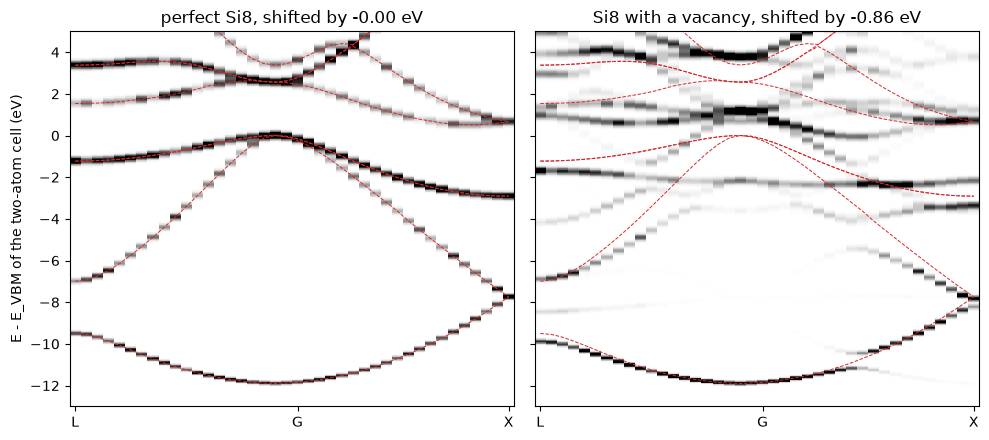

In [3]:
ev, x = 13.6057, np.arange(len(kpoints))
levels = np.asarray(bands.eigenvalues)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, (name, a) in zip(axes, spectra.items()):
    deep = a.energies < a.fermi_energy - 0.5   # align at the bottom of the valence band at Gamma
    shift = a.energies[deep][np.argmax(a.spectral[20][deep])] - levels[20, 0]
    ax.pcolormesh(x, (a.energies - shift - levels[:, 3].max()) * ev, a.spectral.T, cmap='Greys', shading='auto', vmin=0, vmax=np.percentile(a.spectral, 99))
    ax.plot(x, (levels - levels[:, 3].max()) * ev, color='C3', lw=0.7, ls='--')
    ax.set_xticks([0, 20, 39], ['L', 'G', 'X']); ax.set_title(f'{name}, shifted by {shift * ev:+.2f} eV'); ax.set_ylim(-13, 5)
axes[0].set_ylabel('E - E_VBM of the two-atom cell (eV)')
plt.tight_layout()

The dashed lines are the bands of the two-atom cell, with the top of the valence
band at zero. Two different cells have no common zero of energy, because the average
potential is a convention of each cell. So each supercell is shifted to put the bottom
of its valence band at $\Gamma$ on the dashed line, by $-0.005$ eV for the perfect cell
and $-0.86$ eV for the vacancy.

On the left, the weight of the perfect supercell sits on the bands of the two-atom
cell, at every $\mathbf k$. On the right, one atom in eight is removed. The lowest
band survives, a little broadened. The upper valence bands lose much of their
weight, and flat features appear near $-2$ and $+1$ eV. These are the states of the
vacancy, which are localized and so have no single $\mathbf k$.

How much Bloch character survives? Below the Fermi level the perfect crystal has
four occupied bands per spin at each $\mathbf k$, so the integral of $A$ is 4. We
read it from an exact trace at L, $\Gamma$ and X, because with 8 random vectors this
integral has a spread of about 0.7:

In [4]:
for name, w in weights.items():
    print(f'{name:20s} L {w[0]:.3f}   G {w[1]:.3f}   X {w[2]:.3f}')

perfect Si8          L 4.000   G 3.995   X 4.006
Si8 with a vacancy   L 3.250   G 1.786   X 3.747


The perfect cell gives 4 within 0.006, which is the tail of the broadened peaks
across the gap. With the vacancy the weight is lower, most of all at $\Gamma$, where
it is 1.79. Part of the reason is that the cell has 28 electrons instead of 32. The
rest is the weight that moves into the localized states of the vacancy.

For this small cell, the bands of the supercell are cheap too. The method pays for
large supercells, with a dilute defect or with disorder, where the supercell has
thousands of bands. The checks of these numbers are in
`tests/unit/test_kpm_traces.py`: the size of the set of plane waves against the
sphere of the two-atom cell, and the unfolded moments of a perfect supercell
against the exact eigenvalues of that block of the Hamiltonian.